# CUSTOMER CHURN PREDICTION fOR IBM (TELECOMMUNICATIONS COMPANY)


# 1.0 BUSINESS UNDERSTANDING

## 1.1 PROBLEM STATEMENT

IBM wants to reduce customer churn by identifting customers who are likely to leave. High churn rates reduce revenue, increase customer acqusition costs and hinder business growth.
IBM has historical customer data containing demographics, contract types, internet services, payment, tenure, monthly charges and churn status. 
The management needs a predictive system that can flag customers ar risk of churning so they can intervene with retention strategies.

## 1.2 BUSINESS QUESTION

- Can a machine learning be used to predict whether a customer will churn based on their characteristics and service information?

## 1.3 OBJECTIVES

**Main objective**: To develop a predictive model that accurately predicts a customer to churn and deploy it.

- Other objectives are; Conduct an in-depth analysis of the dataset to identify key features that impact customers churning in IBM.
  

# 2.0 Understanding the dataset

The dataset contains historical customer information from IBM company. Each row represents a customer and each column represents a customer attribute such as:

- Demographics (gender, senior citizen, partner, dependents)

- Contract type (month-to-month, one year, two year)

- Internet service (DSL, fiber optic, none)

- Payment method (electronic check, mailed check, bank transfer, credit card)

- Tenure (number of months with the company)

- Monthly charges and total charges

- Subscribed services (online security, tech support, streaming TV, etc.)

- Churn status (target variable: Yes/No)



## 2.1 Imports needed

In [1]:
# ! pip install -r requirements.txt

In [2]:
# imports needed for the project
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

## 2.3 Inspect and  Load the dataset

In [3]:
# load the dataset
df_raw = pd.read_csv("IBM Telco Customer churn.csv") # the original dataset
df = df_raw.copy() # data to use for analysis
display(df_raw.head())
display(df_raw.tail())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [4]:
# Check the shape of the dataset
print(f'The dataset has  {df.shape[0]} rows and {df.shape[1]} columns')

The dataset has  7043 rows and 21 columns


In [5]:
# check column types
print("\n=== Column Types ===")
print(df.dtypes)


=== Column Types ===
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [6]:
# Summary of the dataset
# in terms of missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
# check for duplicates 
n_dupes = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {n_dupes}")



Number of duplicate rows: 0


In [8]:
# The target variable is 'Churn', which indicates whether a customer has churned or not. Let's check the distribution of this variable.
print("\n=== Churn Distribution ===")
churn_counts = df['Churn'].value_counts() * 100 / len(df)
print(churn_counts)


=== Churn Distribution ===
Churn
No     73.463013
Yes    26.536987
Name: count, dtype: float64


- The dataset has 7043 rows and 21 columns.
- The dataset has no duplicates 
- It has no missing values 
- It has 3 numerical columns 
- It has 9 categorical columns
- Though some data columns has unfit data types like *Total charges* which should be a numerical data type(int64).
- Senior_citizen is also encode hence it being a categorical feature(0 not bieng a senior citizen, 1 being senior citizen).
- The target variable(Churn) is a string/object and the is an imbalance whereby 73% of the customers do not churn while 26% of the customers want to leave.
- The customer ID for prediction because it behaves as index doesn't really influence the target variable in any way( should be dropped).

# 3.0 Data preparation and cleaning

In [9]:
# Drop unnecessary columns
df.drop(columns='customerID', inplace=True, errors='ignore')

# correct data type for 'TotalCharges' column
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Convert senior citizen from 0/1  to Yes/No for clear visuals in EDA
df['SeniorCitizen'] = df['SeniorCitizen'].map({1:'Yes', 0: 'No'})

In [10]:
# check missing values
df.isna().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [11]:
# drop the missing values in Total charges 
df = df.dropna()
df.info() 

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   object 
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   object 
 15  PaperlessBilling  7032 non-null   object 
 16  PaymentMethod     7032 non-null   object 
 17  

In [12]:
# check for duplicates 
n_dupes = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {n_dupes}")

# remove the duplicates
df = df.drop_duplicates()
print(f"\nNumber of rows after removing duplicates: {df.shape[0]}")


Number of duplicate rows: 22

Number of rows after removing duplicates: 7010


In [13]:
# check for missing values again
missing_values = df.isna().sum()
print("\n=== Missing Values After Cleaning ===")
print(f"\nNumber of missing values after cleaning: {missing_values.sum()}")

# check for duplicates again
n_dupes = df.duplicated().sum()
print(f"\nNumber of duplicate rows after cleaning: {n_dupes}")


=== Missing Values After Cleaning ===

Number of missing values after cleaning: 0

Number of duplicate rows after cleaning: 0


# 4.0 Exploratory   Data Analysis

## 4.1 Univariate Analysis: Target Variable.

FileNotFoundError: [Errno 2] No such file or directory: '../reports/eda/churn_distribution.png'

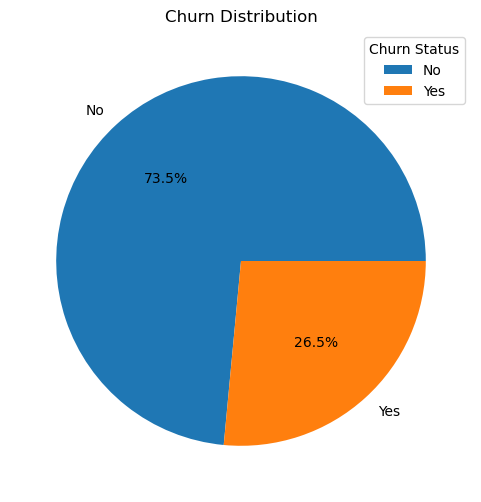

In [15]:
# plot pie chart for churn distribution
plt.figure(figsize=(6, 6))
churn_counts = df['Churn'].value_counts()
plt.pie(churn_counts, labels=churn_counts.index, autopct='%1.1f%%')
plt.legend(title='Churn Status', loc='upper right')
plt.title('Churn Distribution')
plt.savefig("../reports/eda/churn_distribution.png", bbox_inches="tight")
plt.show()

# calculate churn rate for baseline
churn_rate = churn_counts['Yes'] / churn_counts.sum() * 100
print(f"Churn Rate: {churn_rate:.2f}%")

**Key Insights💡**
- **Class imbalance:** The dataset exhibits a significant class imbalance. **73.4% of the customers have not churned("No")**, while **26.6% have churned("Yes")**.

## 4.2 Bivariate Analysis: Categorical features vs. Churn 

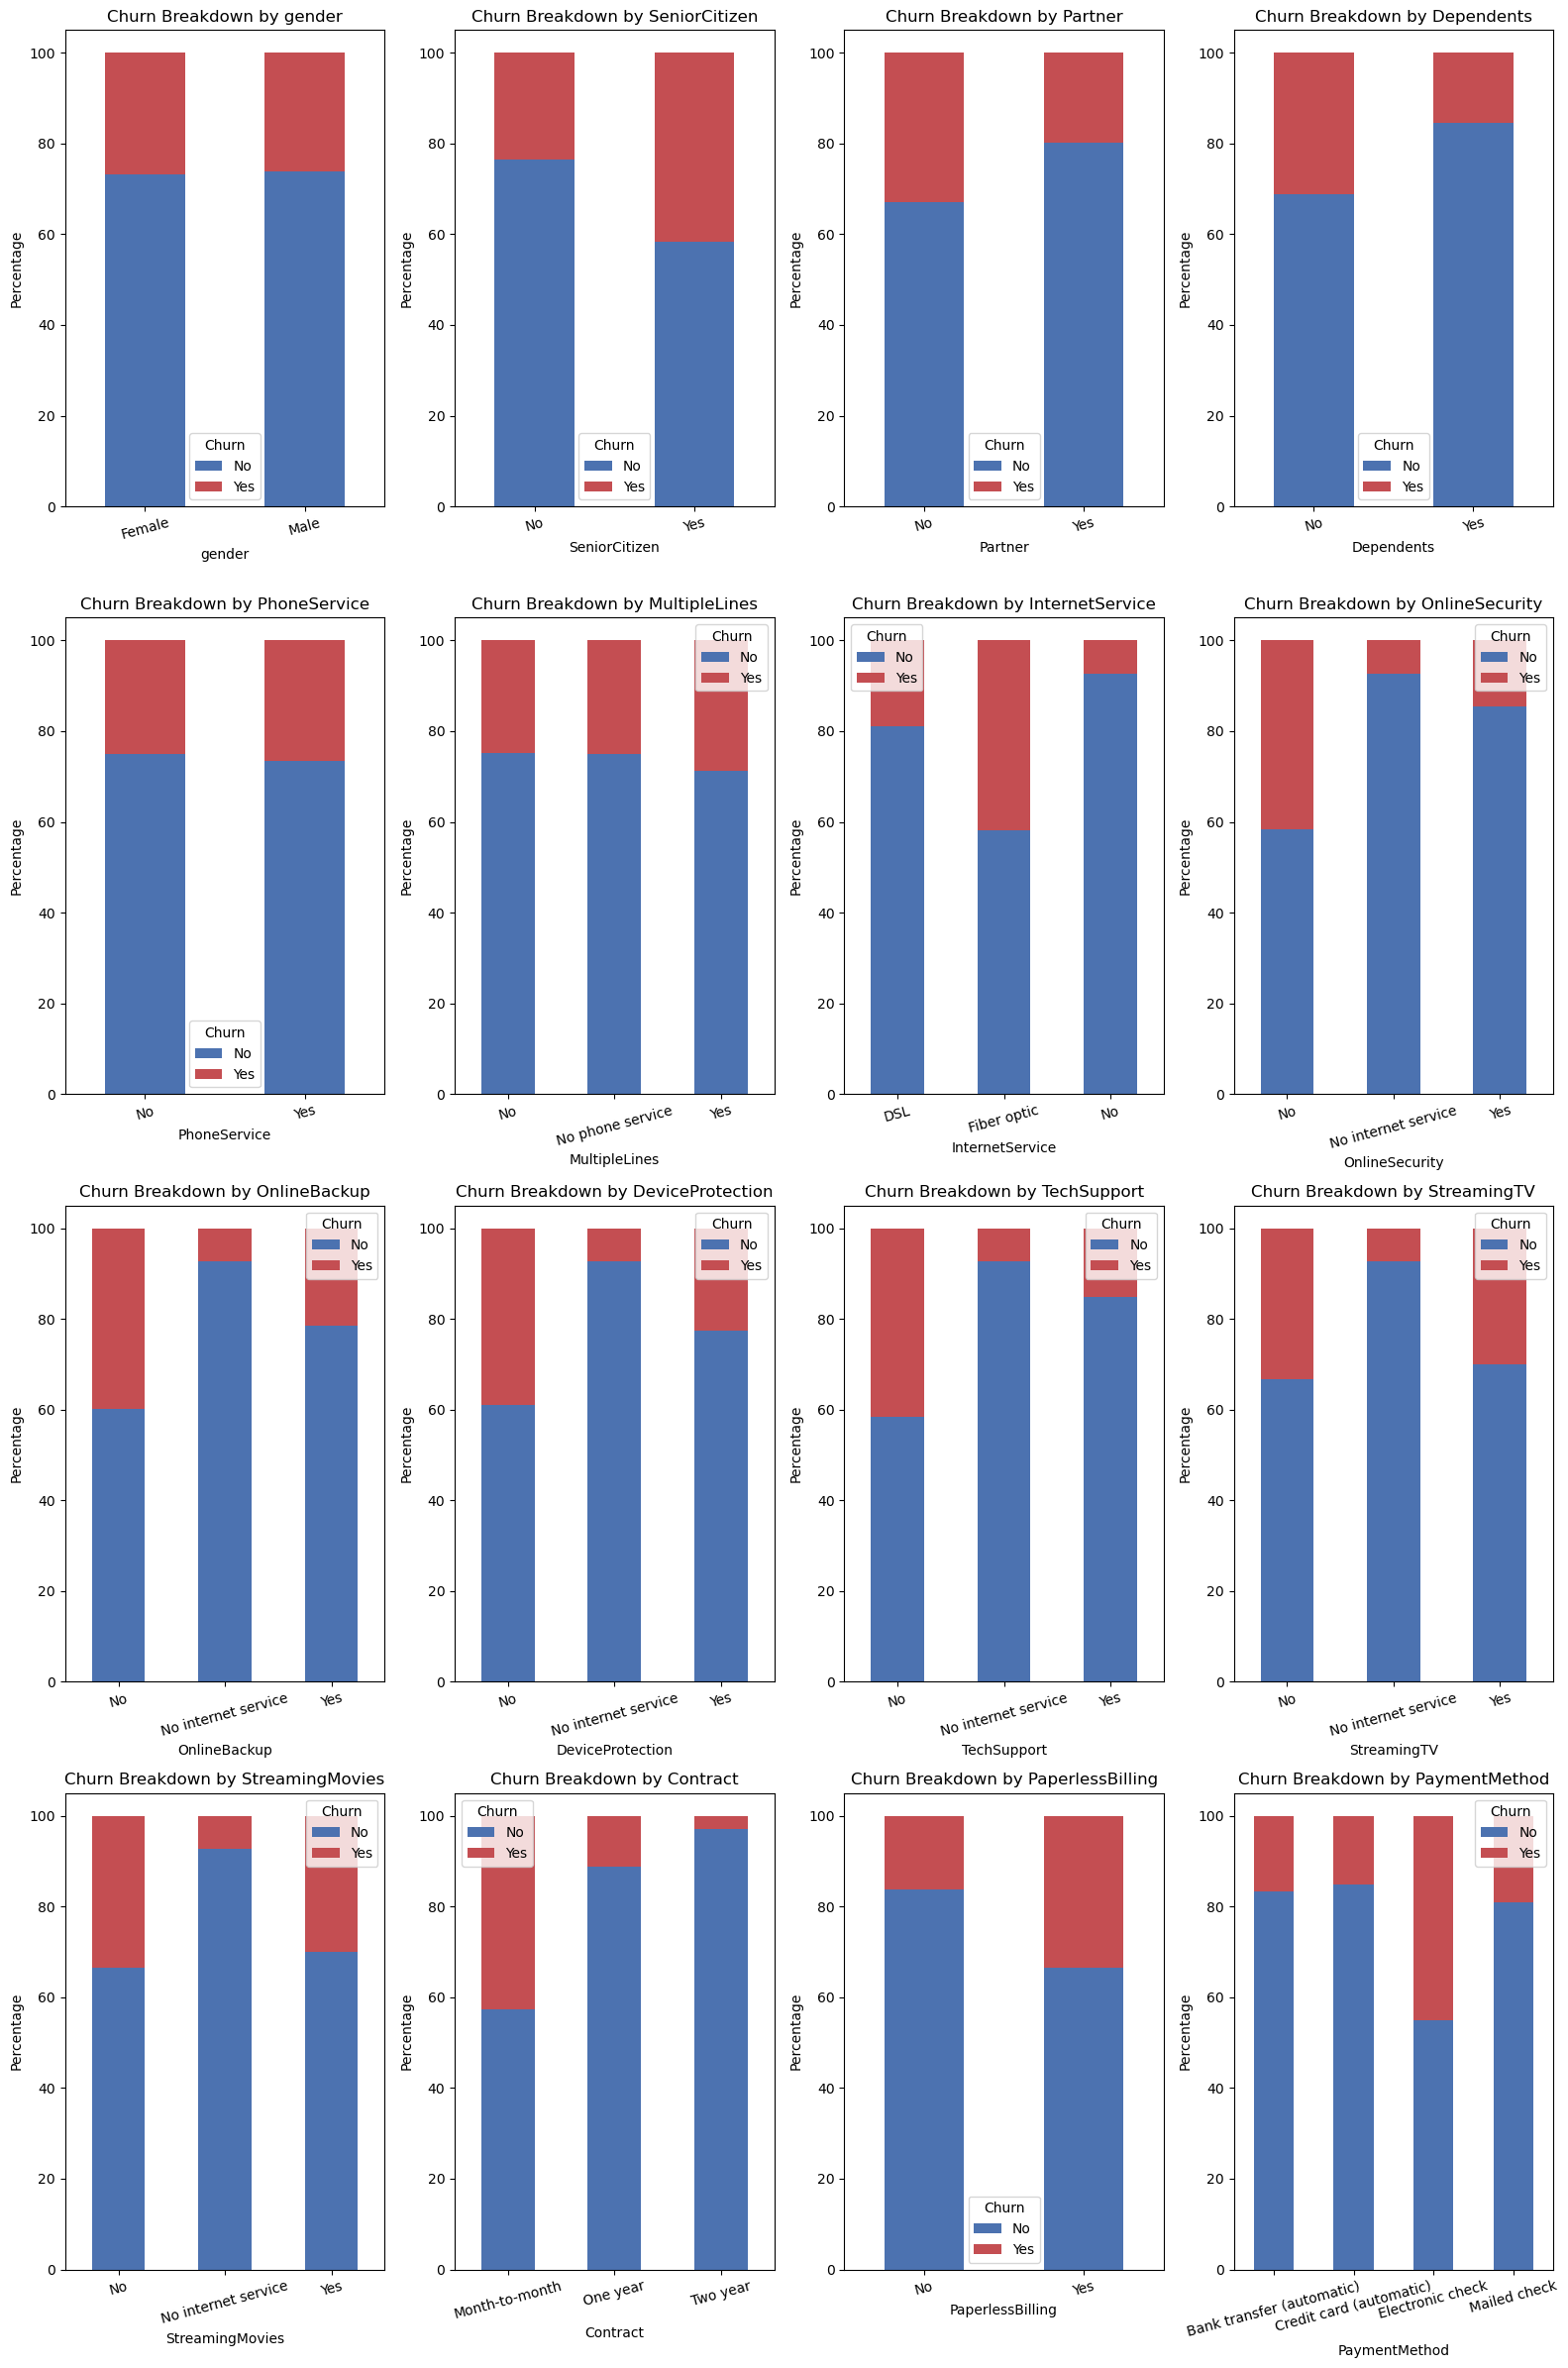

In [ ]:
categorical_cols = df.select_dtypes(include='object').columns

fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,24))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    # Create a normalized percentage  plot for better risk assessment
    if col == 'Churn':
        continue

    df_plot = (
        df.groupby(col, dropna=False)['Churn']
          .value_counts(normalize=True)
          .unstack(fill_value=0) * 100
    )
    df_plot.plot(
        kind="bar",
        stacked=True,
        ax=axes[i],
        color=['#4c72b0','#c44e52']
        )
    axes[i].set_title(f'Churn Breakdown by {col}')
    axes[i].set_ylabel('Percentage')
    axes[i].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('../reports/eda/churn_breakdown_by_categorical_features.png', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
# Loop and calculate percentages
for col in categorical_cols:
    print(f"--- Churn Breakdown by {col} ---")
    percentages = (
        df.groupby(col)['Churn']
        .value_counts(normalize=True)
        .mul(100)
        .round(2)                     # Rounds to 2 decimal places for neatness
        .rename('Percentage')
        .to_frame()                   # Converts to DataFrame for better formatting
    )
    display(percentages)
    print("\n")                       # Adds a blank line between tables

--- Churn Breakdown by gender ---


Percentage
gender Churn            
Female No          73.12
       Yes         26.88
Male   No          73.89
       Yes         26.11



--- Churn Breakdown by SeniorCitizen ---


Percentage
SeniorCitizen Churn            
No            No          76.45
              Yes         23.55
Yes           No          58.37
              Yes         41.63



--- Churn Breakdown by Partner ---


...

Percentage
PaperlessBilling Churn            
No               No          83.66
                 Yes         16.34
Yes              No          66.55
                 Yes         33.45



--- Churn Breakdown by PaymentMethod ---


Percentage
PaymentMethod             Churn            
Bank transfer (automatic) No          83.27
                          Yes         16.73
Credit card (automatic)   No          84.75
                          Yes         15.25
Electronic check          No          54.85
                          Yes         45.15
Mailed check              No          80.98
                          Yes         19.02



--- Churn Breakdown by Churn ---


,Percentage
Churn,
No,100.0
Yes,100.0


### 📊 Key Insights from Categorical Feature Analysis

#### 👤 Demographics
* **Household Ties Over Gender:** Customers living alone (**No Partner** and **No Dependents**) are highly volatile, showing churn rates climbing toward **35% or higher**. Conversely, account ties to family structures drastically increase product stickiness.
* **Age Risk:** **Senior Citizens** represent a high-risk segment, churning at a significantly higher rate (roughly **40% or more**) compared to younger demographics.
* **Low Impact:** **Gender** shows virtually identical distributions between males and females, offering zero predictive power for the machine learning model.

#### 📜 Contract Type
* **The Month-to-Month Hazard:** **Month-to-month** contracts are the single largest risk factor in the dataset, driving an astronomical churn rate **well over 40%**. 
* **Long-Term Lock-In:** Churn drops off a cliff for **One-year** contracts and becomes almost non-existent for **Two-year** contracts, making this the most powerful administrative retention lever.

#### 🌐 Internet Service
* **The Fiber Optic Anomaly:** Customers with **Fiber Optic** internet service exhibit an alarmingly high churn rate, approaching **nearly 40%**. 
* **DSL & Non-Internet Stability:** **DSL** users are much more stable, while customers with no internet service at all have the lowest churn. This suggests fiber optic tiers might suffer from high premium pricing or technical/reliability issues.

#### 💳 Payment Method
* **Electronic Check Alert:** Customers paying manually via **Electronic Check** are the most volatile group in the entire dataset, with a massive churn rate approaching **nearly 50%**.
* **Autopay Stability:** Customers utilizing automated billing options—**Bank Transfer (automatic)** and **Credit Card (automatic)**—have exceptionally low churn rates because they face less recurring monthly payment friction.

#### 🛡️ Subscribed Services
* **Utility & Support Anchor Users:** Customers who do **not** subscribe to **Online Security**, **Tech Support**, **Online Backup**, or **Device Protection** experience extreme churn rates (35%+). Activating these specific utility add-ons heavily anchors customers to the ecosystem.
* **Low Impact:** Entertainment-focused add-ons like **Streaming TV** and **Streaming Movies**, alongside basic **Phone Service**, have a negligible effect on whether a user decides to leave or stay.


### 💡 Executive & Strategic Summary

To maximize customer retention, the business should pivot away from broad demographic targeting (like gender) or entertainment adjustments, and aggressively focus on three operational pillars:

1. **Contract & Payment Migration:** Actively incentivize **Month-to-Month** and **Electronic Check** users to transition to **Fixed-Term Contracts (1 or 2 years)** and **Automated Billing (Autopay via Credit Card/Bank Transfer)**. This operational shift addresses the two highest churn-correlated segments in the dataset.
2. **Value Optimization for Fiber Optic Tiers:** Investigate the underlying causes of the high **Fiber Optic** churn rate (e.g., potential technical issues, price hikes, or customer onboarding friction) to match its retention performance with DSL.
3. **Strategic Service Bundling:** Target high-risk accounts by bundling critical utility features—specifically **Tech Support** and **Online Security**—into standard packages, as these services act as the primary anchors for long-term customer stickiness.


In [ ]:
for col in categorical_cols:
    print(f"\nFrequency distribution for {col}:")
    # as percentage of total
    freq_dist = df[col].value_counts().reset_index()
    freq_dist['percentage'] = (freq_dist['count'] / freq_dist['count'].sum()) * 100
    display(freq_dist.sort_values(by='count', ascending=False))



Frequency distribution for gender:


,gender,count,percentage
0,Male,3535,50.42796
1,Female,3475,49.57204



Frequency distribution for SeniorCitizen:


,SeniorCitizen,count,percentage
0,No,5869,83.723252
1,Yes,1141,16.276748



Frequency distribution for Partner:


...

,PaperlessBilling,count,percentage
0,Yes,4158,59.315264
1,No,2852,40.684736



Frequency distribution for PaymentMethod:


,PaymentMethod,count,percentage
0,Electronic check,2359,33.651926
1,Mailed check,1588,22.653352
2,Bank transfer (automatic),1542,21.997147
3,Credit card (automatic),1521,21.697575



Frequency distribution for Churn:


,Churn,count,percentage
0,No,5153,73.509272
1,Yes,1857,26.490728


## 4.3 Numerical Feature Behaviour

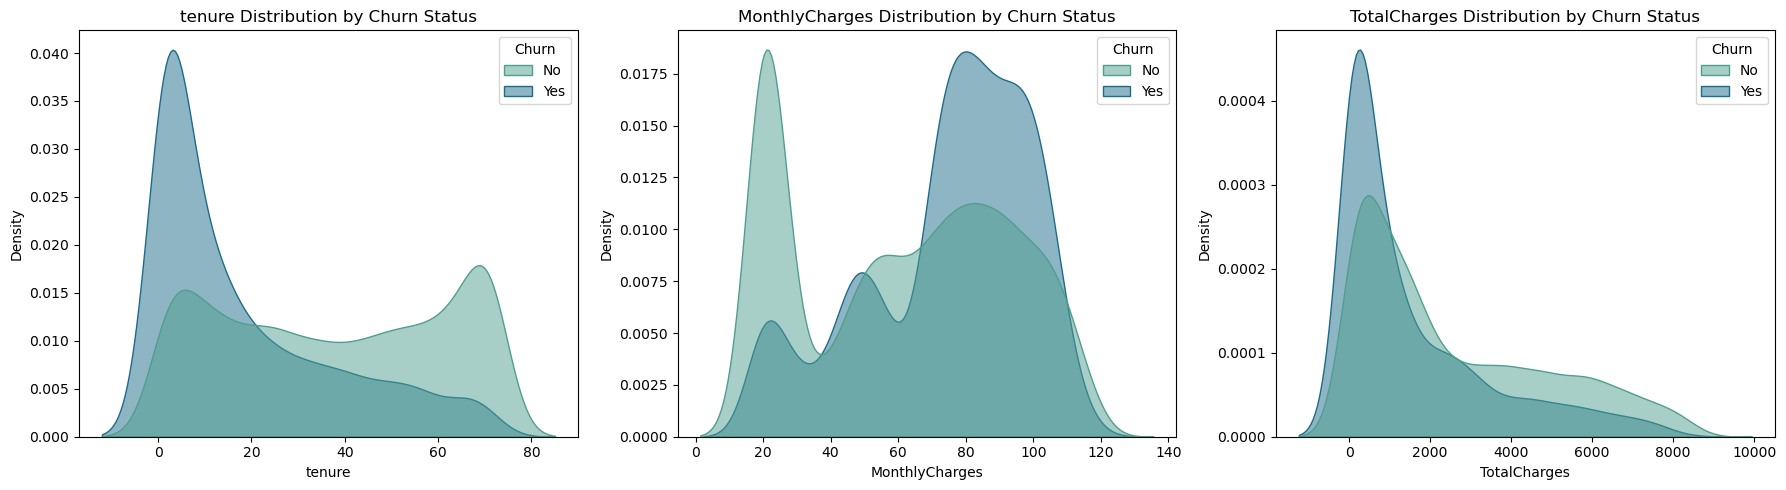

In [ ]:
numerical_cols = df.select_dtypes(exclude='object').columns

fig, axes = plt.subplots(1, 3, figsize=(18,5))

for i, col in enumerate(numerical_cols):
    sns.kdeplot(data=df,
                x=col,
                hue='Churn',
                fill=True,
                common_norm=False,
                palette='crest',
                alpha=0.5,
                ax=axes[i]
                )
    axes[i].set_title(f'{col} Distribution by Churn Status')
plt.tight_layout()
plt.savefig('../reports/eda/numerical_features_distribution_by_churn.png', dpi=300)
plt.show()

    

**Key Insights 💡**

**Tenure Distribution**
- **High Early Risk:** Customers with **low tenure(0-20 months)** show a massive spike in churn("Yes").
- **Long-Term Loyalty:** A tenure increases, the probability of churn drops significantly. Customers who cross the **60+ month mark** are highly likely to stay("No").
- **Take away:** *Onboarding and early-stage engagement* are critical to reducing overall customer loss.

**Monthly Charges Distribution**
- **Premium Price sensitivity:** Churning customers are heavily concentrated in the **higher monthly fee range($70-$110).**
- **Low-Tier stability:** Customers paying low fees ($20) have an extremely low rate of churn.
- **Take away:** Hig-paying tiers might lack a clear value proposition, leading to expensive accounts to cancel.

**Total Charges Distribution**
- **Early exits:** Churn is heavily skewed toward **very low total charges.**
- **Take away:** This reinforces the tenure insight - customers leave before they can accumulate long-term spending, indicating that high upfront or early monthly costs drive them away quickly.

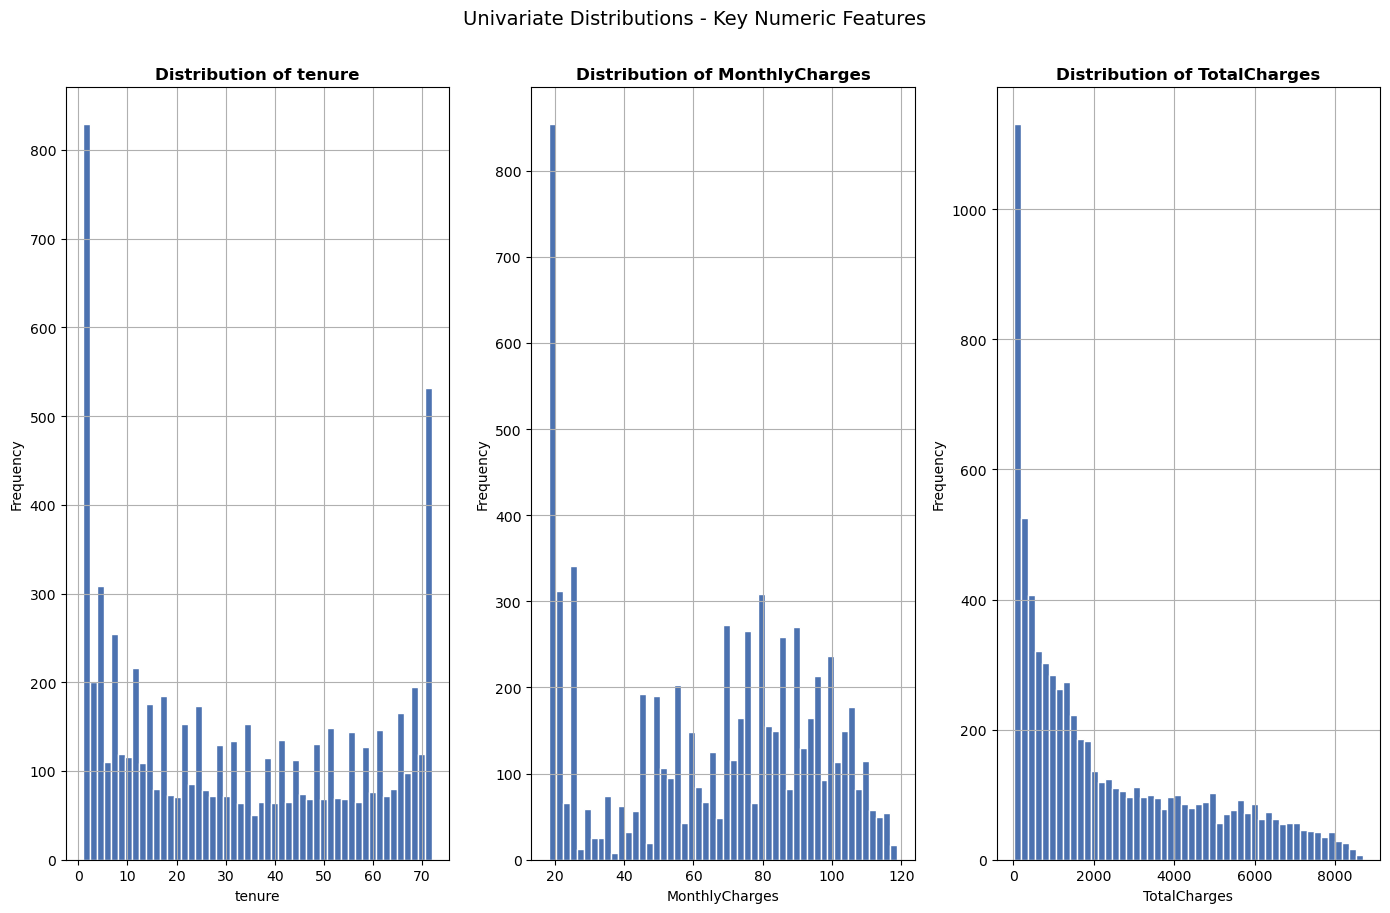

In [ ]:
fig, axes = plt.subplots(1,3, figsize=(14,9))

for ax, col in zip(axes.flatten(), numerical_cols):
    df[col].hist(bins=50, ax=ax, color="#4c72b0", edgecolor="white")
    ax.set_title(f"Distribution of {col}", fontweight="bold")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.suptitle("Univariate Distributions - Key Numeric Features", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('../reports/eda/univariate_distributions_numeric_features.png', dpi=300)
plt.show()

**Key Insights💡**
- **Distribution of tenure:** Shows high frequency for low values
- **Distribution of MonthlyCharges:** Displays varying frequwncies across charge amounts
- **Distribution of TotalCharges:** Is right-skewed, with most customers haviwng lower total charges and fewwer having higher values.

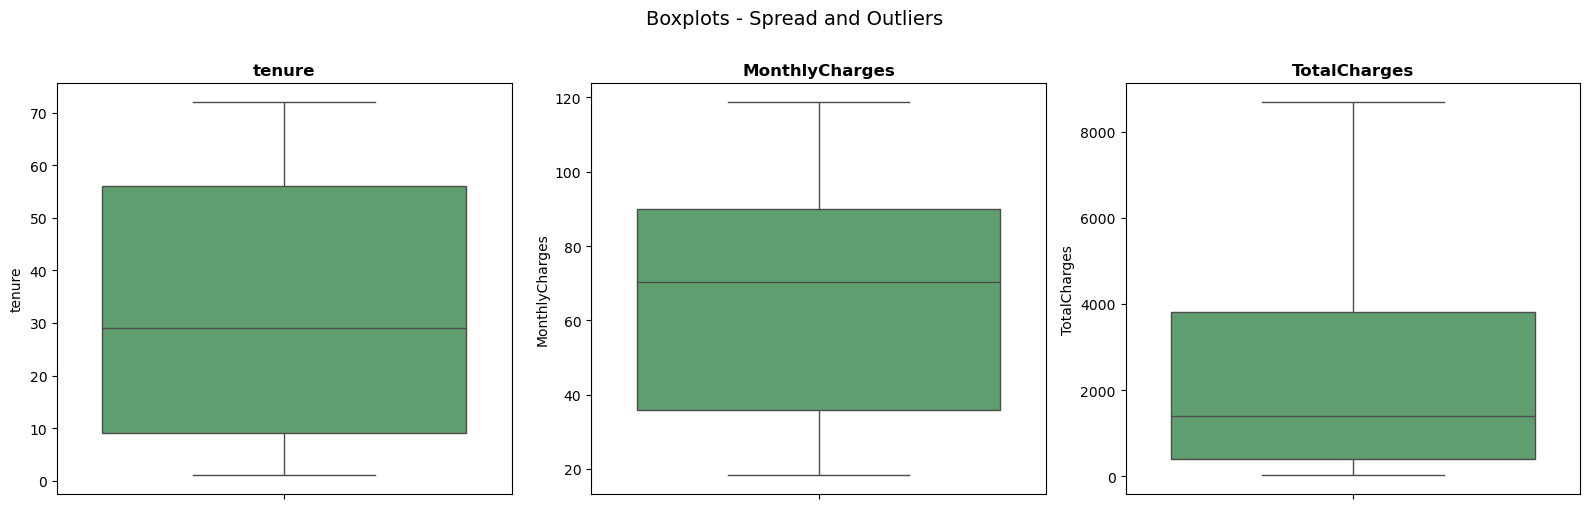

In [ ]:
fig, axes = plt.subplots(1,3, figsize=(16,5))

for ax, col in zip(axes, numerical_cols):
    sns.boxplot(y=df[col], ax=ax, color="#55a868", flierprops=dict(marker=".", alpha=0.3))
    ax.set_title(col, fontweight="bold")

plt.suptitle("Boxplots - Spread and Outliers", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('../reports/eda/boxplots_numeric_features.png', dpi=300)
plt.show()


**Key Insights💡**
- **No Statistical outliers:** Boxplots of the numerical variables show no obvious outliers **(no indiviual data points plotted beyond the whisker)**, suggesting the data follows a realistic distribution without extreme anomalous values.

# 5.0 Modelling

In [ ]:
# Define X and y as Features and target 
X = df.drop(['Churn'], axis= 1) # Features
y = df['Churn'] # target variable




In [ ]:
# convert target variable using mapping 
y = y.map({"No":0, "Yes": 1})


In [ ]:
# feature
display(X.head())

# Target Variable
display(y.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

## 5.1 Train splitting and Identifying Categorical and Numerical features

In [ ]:
# split the data into Train and test data first with original columns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=66
)

In [ ]:
categories = df.select_dtypes(include="object").columns
for col in categories:
    print(f'\n{col}:')
    display(df[col].unique())


gender:


array(['Female', 'Male'], dtype=object)


SeniorCitizen:


array(['No', 'Yes'], dtype=object)


Partner:


...

array(['Yes', 'No'], dtype=object)


PaymentMethod:


array(['Electronic check', 'Mailed check', 'Bank transfer (automatic)',
       'Credit card (automatic)'], dtype=object)


Churn:


array(['No', 'Yes'], dtype=object)

In [ ]:
 # identify categorical features and separate them from numerical features
categorical_features = X_train.select_dtypes(include='object').columns
print(categorical_features)

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod'],
      dtype='object')


In [ ]:
# identify numerical features nad separate them from categorical features
numerical_features = X_train.select_dtypes(exclude='object').columns
print(numerical_features)

Index(['tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')


## 5.2 Encoding Categorical Features and Scaling Numerical Features

In [ ]:
# Create an encoder using OneHotEncoding & fit it on X_train features first.(categorical features) 
encoder = OneHotEncoder(handle_unknown='ignore', drop='first')

X_train_encoded = encoder.fit_transform(X_train[categorical_features])

X_test_encoded = encoder.transform(X_test[categorical_features])

# Prepare numerical features 
X_train_numerical = X_train[numerical_features]
X_test_numerical = X_test[numerical_features]

# Scale numerical features 
scaler = StandardScaler()

X_train_numerical_scaled = scaler.fit_transform(X_train_numerical)
X_test_numerical_scaled = scaler.transform(X_test_numerical)

In [ ]:
# Convert X_encoded in DataFrames since they are in Series

X_train_encoded = pd.DataFrame(
    X_train_encoded.toarray(),
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded.toarray(),
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_test.index
)

# convert scaled numerics back to dataframes
X_train_numerical_scaled = pd.DataFrame(
    X_train_numerical_scaled,
    columns=numerical_features,
    index=X_train.index
)
X_test_numerical_scaled = pd.DataFrame(
    X_test_numerical_scaled,
    columns=numerical_features,
    index=X_test.index

)


In [ ]:
# # view how the encoding and scaling has become
# X_train_encoded
# X_train_numerical_scaled

In [ ]:
# Now Combine the dataframes  with numeric features

X_train_final = pd.concat([X_train_encoded, X_train_numerical_scaled], axis=1)
X_test_final = pd.concat([X_test_encoded, X_test_numerical_scaled], axis=1)

## 5.3 Logistic Regression Model

In [ ]:
# fit the model on the training data
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_final, y_train)

# predict X_test data using  trained model
y_pred = lr.predict(X_test_final)

# Make an evaluation based on the y_test
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1031
           1       0.65      0.54      0.59       371

    accuracy                           0.80      1402
   macro avg       0.75      0.72      0.73      1402
weighted avg       0.79      0.80      0.80      1402



## 5.4 Random Forest Classifier Model

In [ ]:
rf = RandomForestClassifier(n_estimators=1000, random_state=42)
rf.fit(X_train_final, y_train)

y_pred =rf.predict(X_test_final)

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1031
           1       0.62      0.51      0.56       371

    accuracy                           0.79      1402
   macro avg       0.72      0.70      0.71      1402
weighted avg       0.78      0.79      0.78      1402

